# CMSE 201 Final Project 

#### CMSE 201 Final Project
### &#9989; Owen Sylvester
### &#9989; Section_002
#### &#9989; 11/19/2025

# ___How did the Ballon d’Or winner, Ousmane Dembélé, compare against the other nominees?___

## Background and Motivation

_Growing up watching Ronaldo and Messi, almost every season one of them won the Ballon d'Or, and no one batted an eye. Now that they are both in the tail end of their careers, the award has some parity to it. I decided to look more into the key factors in hopes of finding why the winner is the winner. The three main criteria that the award is based on are:
1) Individual performances, decisive, and impressive character
2) Team performances and achievements
3) Class and fair play \
How did the 2025 winner, Ousmane Dembélé, achieve these compared to the other nominees, and which was the most important criterion?_

Data Context Statement:
1. Who collected/generated the data?\
The Ballon d'Or 2025 Nominees Players Standard Stats data set was compiled from FBref, a website that provides detailed statistics for soccer players worldwide. It was then posted on Kaggle by Siddhraj Thakor.
2. How was the data collected/generated?\
The data was generated from official match statistics and therefore does not have any bias. As for the nominee list, it was verified by UEFA.   
3. Who/what is included in the data?\
The data set includes the top 30 nominees of the 2025 Ballon d'Or award. It features stats including their name, position, club, league, goals, assists, minutes played, yellow and red cards, and progressive actions. Specifically, it features the winner Ousmane Dembélé. Dembélé is an attacking winger who plays for PSG in the French league.
4. Who/what is not included in the data?\
What's not included are the players' statistics outside of league play, as well as their respective team performances.
5. What are the limitations or biases of the data?\
One limitation of the data is that it does not include goalkeeper statistics, even though one goalkeeper was nominated. Secondly, team quality, as well as league quality, may affect players' stats. Additionally, Dembele was injured for part of the season, which affected his statistics. Lastly, class and fair play a very subjective variables when taking them into account.
6. Based on the questions you've had to reflect on above, what are you going to do in your project because of this?\
I will compare the key stats in the data set, highlighting Dembele, to compare individual performances. Furthermore, I will use a normalized value of goals and assists per 90 minutes to make up for the matches in which Dembele was injured. As for the other limitations, I plan to ignore the goalkeeper, as only one goalkeeper has won the award, Lev Yashin in 1963. Secondly, I will use secondary data to compare team and individual accomplishments. Lastly, for class and fair play, I will take into account the cards received, as well as researching their charitable actions.

## Methodology

_(How did you go about answering your question(s)? Most of your code will be
contained in this section.)_

To start, I imported the necessary libraries to load and visualize the data. I used Pandas to load the dataset.

In [162]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy.optimize import curve_fit

In [200]:
#Load in the dataset
ballondor = pd.read_csv('ballondor_2025_nominees_dataset.csv')
ballondor.head()

,Rk,Player,Nation,Pos,Squad,Age,Born,MP,Starts,Min,...,AstPer90,G+APer90,G-PKPer90,G+A-PKPer90,xGPer90,xAGPer90,xG+xAGPer90,npxGPer90,npxG+xAGPer90,League
0,228,Achraf Hakimi,ma MAR,DF,Paris S-G,25,1998,25,24,2066,...,0.26,0.44,0.17,0.44,0.13,0.27,0.40,0.13,0.40,Ligue 1
1,319,Alexis Mac Allister,ar ARG,MF,Liverpool,25,1998,35,30,2599,...,0.17,0.35,0.17,0.35,0.10,0.16,0.26,0.10,0.26,Premier League
2,408,Cole Palmer,eng ENG,"MF,FW",Chelsea,22,2002,37,36,3191,...,0.23,0.65,0.31,0.54,0.49,0.31,0.79,0.38,0.68,Premier League
3,435,Declan Rice,eng ENG,MF,Arsenal,25,1999,35,33,2825,...,0.22,0.35,0.13,0.35,0.11,0.21,0.32,0.11,0.32,Premier League
4,180,Denzel Dumfries,nl NED,"DF,FW",Inter,28,1996,29,20,1955,...,0.09,0.41,0.32,0.41,0.25,0.15,0.40,0.25,0.40,Serie A


After loading the dataset, I created several other dataframes to view separate data more easily, filtering out different data in each to do so. The separate dataframes include a dataframe without Dembele, which was used to plot Dembele separately, without him appearing in the legend twice. Additionally, I created a data frame with only forwards and attacking midfielders, as historically they have dominated the award. Furthermore, I isolated each league, 6 total, to compare the strengths of each league and respective teams, as a player on a worse team may have his stats negatively impacted. In contrast, a player in a bad league may have his stats inflated due to the level of competition.

In [165]:
# Dembele's stats
dembele = ballondor_player.loc[["Ousmane Dembélé"]]
dembele

,Rk,Nation,Pos,Squad,Age,Born,MP,Starts,Min,90s,...,AstPer90,G+APer90,G-PKPer90,G+A-PKPer90,xGPer90,xAGPer90,xG+xAGPer90,npxGPer90,npxG+xAGPer90,League
Player,,,,,,,,,,,,,,,,,,,,,
Ousmane Dembélé,151,fr FRA,FW,Paris S-G,27,1997,29,20,1730,19.2,...,0.31,1.4,1.04,1.35,0.86,0.43,1.29,0.82,1.25,Ligue 1


In [201]:
# Create a df indexing by player
ballondor_player = ballondor.set_index("Player")
ballondor_player.head()

,Rk,Nation,Pos,Squad,Age,Born,MP,Starts,Min,90s,...,AstPer90,G+APer90,G-PKPer90,G+A-PKPer90,xGPer90,xAGPer90,xG+xAGPer90,npxGPer90,npxG+xAGPer90,League
Player,,,,,,,,,,,,,,,,,,,,,
Achraf Hakimi,228,ma MAR,DF,Paris S-G,25,1998,25,24,2066,23.0,...,0.26,0.44,0.17,0.44,0.13,0.27,0.40,0.13,0.40,Ligue 1
Alexis Mac Allister,319,ar ARG,MF,Liverpool,25,1998,35,30,2599,28.9,...,0.17,0.35,0.17,0.35,0.10,0.16,0.26,0.10,0.26,Premier League
Cole Palmer,408,eng ENG,"MF,FW",Chelsea,22,2002,37,36,3191,35.5,...,0.23,0.65,0.31,0.54,0.49,0.31,0.79,0.38,0.68,Premier League
Declan Rice,435,eng ENG,MF,Arsenal,25,1999,35,33,2825,31.4,...,0.22,0.35,0.13,0.35,0.11,0.21,0.32,0.11,0.32,Premier League
Denzel Dumfries,180,nl NED,"DF,FW",Inter,28,1996,29,20,1955,21.7,...,0.09,0.41,0.32,0.41,0.25,0.15,0.40,0.25,0.40,Serie A


In [166]:
# French League
france = ballondor[ballondor['League'] == "Ligue 1"]
france

,Rk,Player,Nation,Pos,Squad,Age,Born,MP,Starts,Min,...,AstPer90,G+APer90,G-PKPer90,G+A-PKPer90,xGPer90,xAGPer90,xG+xAGPer90,npxGPer90,npxG+xAGPer90,League
0,228,Achraf Hakimi,ma MAR,DF,Paris S-G,25,1998,25,24,2066,...,0.26,0.44,0.17,0.44,0.13,0.27,0.40,0.13,0.40,Ligue 1
5,174,Désiré Doué,fr FRA,"FW,MF",Paris S-G,19,2005,31,18,1730,...,0.31,0.62,0.31,0.62,0.27,0.41,0.67,0.27,0.67,Ligue 1
8,172,Gianluigi Donnarumma,it ITA,GK,Paris S-G,25,1999,24,24,2091,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,Ligue 1
10,394,João Neves,pt POR,"MF,DF",Paris S-G,19,2004,29,22,1844,...,0.39,0.54,0.15,0.54,0.15,0.20,0.34,0.15,0.34,Ligue 1
13,288,Khvicha Kvaratskhelia,ge GEO,FW,Paris S-G,23,2001,14,11,916,...,0.29,0.69,0.39,0.69,0.32,0.48,0.80,0.32,0.80,Ligue 1
19,354,Nuno Mendes,pt POR,DF,Paris S-G,22,2002,24,19,1676,...,0.16,0.21,0.05,0.21,0.12,0.27,0.39,0.12,0.39,Ligue 1
20,151,Ousmane Dembélé,fr FRA,FW,Paris S-G,27,1997,29,20,1730,...,0.31,1.40,1.04,1.35,0.86,0.43,1.29,0.82,1.25,Ligue 1
29,534,Vitinha,pt POR,MF,Paris S-G,24,2000,29,20,2042,...,0.04,0.26,0.13,0.18,0.15,0.11,0.27,0.08,0.20,Ligue 1


In [202]:
# Ballondor dataset without dembele to remove Dembele from the legend, and make it easier to remove him from other filtered data sets
no_dembele = ballondor[ballondor['Player'] != 'Ousmane Dembélé'] # I asked chatGPT how to remove one player and it told me to use !=
no_dembele

,Rk,Player,Nation,Pos,Squad,Age,Born,MP,Starts,Min,...,AstPer90,G+APer90,G-PKPer90,G+A-PKPer90,xGPer90,xAGPer90,xG+xAGPer90,npxGPer90,npxG+xAGPer90,League
0,228,Achraf Hakimi,ma MAR,DF,Paris S-G,25,1998,25,24,2066,...,0.26,0.44,0.17,0.44,0.13,0.27,0.40,0.13,0.40,Ligue 1
1,319,Alexis Mac Allister,ar ARG,MF,Liverpool,25,1998,35,30,2599,...,0.17,0.35,0.17,0.35,0.10,0.16,0.26,0.10,0.26,Premier League
2,408,Cole Palmer,eng ENG,"MF,FW",Chelsea,22,2002,37,36,3191,...,0.23,0.65,0.31,0.54,0.49,0.31,0.79,0.38,0.68,Premier League
3,435,Declan Rice,eng ENG,MF,Arsenal,25,1999,35,33,2825,...,0.22,0.35,0.13,0.35,0.11,0.21,0.32,0.11,0.32,Premier League
4,180,Denzel Dumfries,nl NED,"DF,FW",Inter,28,1996,29,20,1955,...,0.09,0.41,0.32,0.41,0.25,0.15,0.40,0.25,0.40,Serie A
5,174,Désiré Doué,fr FRA,"FW,MF",Paris S-G,19,2005,31,18,1730,...,0.31,0.62,0.31,0.62,0.27,0.41,0.67,0.27,0.67,Ligue 1
6,225,Erling Haaland,no NOR,FW,Manchester City,24,2000,31,31,2736,...,0.10,0.82,0.62,0.72,0.72,0.10,0.82,0.62,0.72,Premier League
7,478,Florian Wirtz,de GER,"MF,FW",Leverkusen,21,2003,31,25,2351,...,0.46,0.84,0.31,0.77,0.36,0.27,0.63,0.23,0.50,Bundesliga
8,172,Gianluigi Donnarumma,it ITA,GK,Paris S-G,25,1999,24,24,2091,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,Ligue 1
9,207,Harry Kane,eng ENG,FW,Bayern Munich,31,1993,31,28,2381,...,0.34,1.32,0.64,0.98,0.77,0.20,0.97,0.50,0.70,Bundesliga


In [203]:
# France data set without Dembele to remove Dembele from the legend when plotting
france2 = no_dembele[no_dembele['League'] == "Ligue 1"]
france2

,Rk,Player,Nation,Pos,Squad,Age,Born,MP,Starts,Min,...,AstPer90,G+APer90,G-PKPer90,G+A-PKPer90,xGPer90,xAGPer90,xG+xAGPer90,npxGPer90,npxG+xAGPer90,League
0,228,Achraf Hakimi,ma MAR,DF,Paris S-G,25,1998,25,24,2066,...,0.26,0.44,0.17,0.44,0.13,0.27,0.40,0.13,0.40,Ligue 1
5,174,Désiré Doué,fr FRA,"FW,MF",Paris S-G,19,2005,31,18,1730,...,0.31,0.62,0.31,0.62,0.27,0.41,0.67,0.27,0.67,Ligue 1
8,172,Gianluigi Donnarumma,it ITA,GK,Paris S-G,25,1999,24,24,2091,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,Ligue 1
10,394,João Neves,pt POR,"MF,DF",Paris S-G,19,2004,29,22,1844,...,0.39,0.54,0.15,0.54,0.15,0.20,0.34,0.15,0.34,Ligue 1
13,288,Khvicha Kvaratskhelia,ge GEO,FW,Paris S-G,23,2001,14,11,916,...,0.29,0.69,0.39,0.69,0.32,0.48,0.80,0.32,0.80,Ligue 1
19,354,Nuno Mendes,pt POR,DF,Paris S-G,22,2002,24,19,1676,...,0.16,0.21,0.05,0.21,0.12,0.27,0.39,0.12,0.39,Ligue 1
29,534,Vitinha,pt POR,MF,Paris S-G,24,2000,29,20,2042,...,0.04,0.26,0.13,0.18,0.15,0.11,0.27,0.08,0.20,Ligue 1


In [169]:
# Forwards
fws = ballondor[(ballondor['Pos'] == "FW") | (ballondor['Pos'] == "FW,MF") | (ballondor['Pos'] == "MF,FW")]
fws

,Rk,Player,Nation,Pos,Squad,Age,Born,MP,Starts,Min,...,AstPer90,G+APer90,G-PKPer90,G+A-PKPer90,xGPer90,xAGPer90,xG+xAGPer90,npxGPer90,npxG+xAGPer90,League
2,408,Cole Palmer,eng ENG,"MF,FW",Chelsea,22,2002,37,36,3191,...,0.23,0.65,0.31,0.54,0.49,0.31,0.79,0.38,0.68,Premier League
5,174,Désiré Doué,fr FRA,"FW,MF",Paris S-G,19,2005,31,18,1730,...,0.31,0.62,0.31,0.62,0.27,0.41,0.67,0.27,0.67,Ligue 1
6,225,Erling Haaland,no NOR,FW,Manchester City,24,2000,31,31,2736,...,0.10,0.82,0.62,0.72,0.72,0.10,0.82,0.62,0.72,Premier League
7,478,Florian Wirtz,de GER,"MF,FW",Leverkusen,21,2003,31,25,2351,...,0.46,0.84,0.31,0.77,0.36,0.27,0.63,0.23,0.50,Bundesliga
9,207,Harry Kane,eng ENG,FW,Bayern Munich,31,1993,31,28,2381,...,0.34,1.32,0.64,0.98,0.77,0.20,0.97,0.50,0.70,Bundesliga
12,311,Khvicha Kvaratskhelia,ge GEO,"FW,MF",Napoli,23,2001,17,15,1178,...,0.23,0.61,0.31,0.53,0.32,0.28,0.60,0.26,0.54,Serie A
13,288,Khvicha Kvaratskhelia,ge GEO,FW,Paris S-G,23,2001,14,11,916,...,0.29,0.69,0.39,0.69,0.32,0.48,0.80,0.32,0.80,Ligue 1
14,360,Kylian Mbappé,fr FRA,FW,Real Madrid,25,1998,34,34,2907,...,0.09,1.05,0.74,0.84,0.80,0.24,1.04,0.58,0.81,La Liga
15,595,Lamine Yamal,es ESP,FW,Barcelona,17,2007,35,31,2856,...,0.41,0.69,0.28,0.69,0.31,0.44,0.75,0.31,0.75,La Liga
16,367,Lautaro Martínez,ar ARG,FW,Inter,26,1997,31,31,2564,...,0.11,0.53,0.42,0.53,0.47,0.15,0.62,0.47,0.62,Serie A


In [204]:
# Fws data set without Dembele, to remove Dembele from the legend when plotting
fws2 = no_dembele[(no_dembele['Pos'] == "FW") | (no_dembele['Pos'] == "FW,MF") | (no_dembele['Pos'] == "MF,FW")]
fws2

,Rk,Player,Nation,Pos,Squad,Age,Born,MP,Starts,Min,...,AstPer90,G+APer90,G-PKPer90,G+A-PKPer90,xGPer90,xAGPer90,xG+xAGPer90,npxGPer90,npxG+xAGPer90,League
2,408,Cole Palmer,eng ENG,"MF,FW",Chelsea,22,2002,37,36,3191,...,0.23,0.65,0.31,0.54,0.49,0.31,0.79,0.38,0.68,Premier League
5,174,Désiré Doué,fr FRA,"FW,MF",Paris S-G,19,2005,31,18,1730,...,0.31,0.62,0.31,0.62,0.27,0.41,0.67,0.27,0.67,Ligue 1
6,225,Erling Haaland,no NOR,FW,Manchester City,24,2000,31,31,2736,...,0.10,0.82,0.62,0.72,0.72,0.10,0.82,0.62,0.72,Premier League
7,478,Florian Wirtz,de GER,"MF,FW",Leverkusen,21,2003,31,25,2351,...,0.46,0.84,0.31,0.77,0.36,0.27,0.63,0.23,0.50,Bundesliga
9,207,Harry Kane,eng ENG,FW,Bayern Munich,31,1993,31,28,2381,...,0.34,1.32,0.64,0.98,0.77,0.20,0.97,0.50,0.70,Bundesliga
12,311,Khvicha Kvaratskhelia,ge GEO,"FW,MF",Napoli,23,2001,17,15,1178,...,0.23,0.61,0.31,0.53,0.32,0.28,0.60,0.26,0.54,Serie A
13,288,Khvicha Kvaratskhelia,ge GEO,FW,Paris S-G,23,2001,14,11,916,...,0.29,0.69,0.39,0.69,0.32,0.48,0.80,0.32,0.80,Ligue 1
14,360,Kylian Mbappé,fr FRA,FW,Real Madrid,25,1998,34,34,2907,...,0.09,1.05,0.74,0.84,0.80,0.24,1.04,0.58,0.81,La Liga
15,595,Lamine Yamal,es ESP,FW,Barcelona,17,2007,35,31,2856,...,0.41,0.69,0.28,0.69,0.31,0.44,0.75,0.31,0.75,La Liga
16,367,Lautaro Martínez,ar ARG,FW,Inter,26,1997,31,31,2564,...,0.11,0.53,0.42,0.53,0.47,0.15,0.62,0.47,0.62,Serie A


In [171]:
#Isolating the other leagues 
germany = ballondor[ballondor['League'] == "Bundesliga"]
england = ballondor[ballondor['League'] == "Premier League"]
spain = ballondor[ballondor['League'] == "La Liga"]
portugal = ballondor[ballondor['League'] == "Primeira Liga"]
italy = ballondor[ballondor['League'] == "Serie A"]

print(f'{len(france)} players in France')
print(f'{len(england)} players in England')
print(f'{len(spain)} players in Spain')
print(f'{len(germany)} players in Germany')
print(f'{len(italy)} players in Italy')
print(f'{len(portugal)} players in Portugal')

8 players in France
7 players in England
6 players in Spain
4 players in Germany
4 players in Italy
1 players in Portugal


After filtering, I compared the total goals vs assists for all forwards, since they are the most important metric of a forward. I chose to compare the total of both because it shows more of the player's impact on the field. Additionally, comparing just goals or just assists would limit the impact of wingers or strikers.

In [174]:
# Goals + Assists ranking for all forwards
fws[['Player', 'G+A']].sort_values(by='G+A', ascending=False)

,Player,G+A
18,Mohamed Salah,47
27,Viktor Gyökeres,46
9,Harry Kane,35
14,Kylian Mbappé,34
23,Robert Lewandowski,29
17,Michael Olise,27
22,Raphinha,27
20,Ousmane Dembélé,27
6,Erling Haaland,25
26,Serhou Guirassy,25


To understand why Dembele was in the middle of the pack, I compared the minutes for every player. After seeing that he was towards the bottom, I learned that he had a calf injury and missed a month of the season. To make up for the missed time, I compared each forward's goals and assists per 90 minutes. Doing so highlighted his impact despite the missed games. Furthermore, I compared each player's expected goals and assists per 90 minutes, as it is a normalized value, completely removing the impacts of a player having more or less minutes than another. Expected goals and assists are calculated by the quality of chances a player creates during a game. Each chance created is valued between 0-1, with better quality chances having a higher value. To sort the values, I used sort_values from Pandas.

In [176]:
# Compare total minutes played for all players in the dataset
ballondor[['Player', 'Min']].sort_values(by='Min', ascending=False)

,Player,Min
18,Mohamed Salah,3371
28,Virgil van Dijk,3330
2,Cole Palmer,3191
24,Scott McTominay,2938
14,Kylian Mbappé,2907
21,Pedri,2879
15,Lamine Yamal,2856
22,Raphinha,2839
3,Declan Rice,2825
27,Viktor Gyökeres,2804


In [179]:
fws[['Player', 'G+APer90']].sort_values(by='G+APer90', ascending=False)

,Player,G+APer90
27,Viktor Gyökeres,1.48
20,Ousmane Dembélé,1.40
9,Harry Kane,1.32
18,Mohamed Salah,1.25
14,Kylian Mbappé,1.05
17,Michael Olise,1.04
23,Robert Lewandowski,0.98
26,Serhou Guirassy,0.87
22,Raphinha,0.86
7,Florian Wirtz,0.84


In [182]:
# Expected Goals per 90 mins + Expected Assists per 90 mins ranking for all forwards
fws[['Player', 'xG+xAGPer90']].sort_values(by='xG+xAGPer90', ascending=False)

,Player,xG+xAGPer90
20,Ousmane Dembélé,1.29
27,Viktor Gyökeres,1.22
18,Mohamed Salah,1.05
14,Kylian Mbappé,1.04
22,Raphinha,1.01
23,Robert Lewandowski,0.99
9,Harry Kane,0.97
26,Serhou Guirassy,0.92
17,Michael Olise,0.84
6,Erling Haaland,0.82


While penalty kicks do take skill, they can inflate a striker's goal total since, traditionally, they are the ones taking them. Sorting by penalty kicks attempted, as well as penalty kicks attempted for PSG players, we can better understand which players are taking advantage of being their team's penalty taker. After sorting, I also analyzed the expected goals and assists excluding penalty kicks value to if Dembele's lead was extended.

In [183]:
# Penalty Kicks attempted for all forwards
fws[['Player', 'PKatt']].sort_values(by='PKatt', ascending=False)

,Player,PKatt
27,Viktor Gyökeres,12
9,Harry Kane,9
18,Mohamed Salah,9
14,Kylian Mbappé,9
2,Cole Palmer,5
7,Florian Wirtz,4
6,Erling Haaland,4
23,Robert Lewandowski,4
26,Serhou Guirassy,4
22,Raphinha,2


In [184]:
# Penalty Kicks attempted for all PSG players
france[['Player', 'PKatt']].sort_values(by='PKatt', ascending=False)

,Player,PKatt
29,Vitinha,2
20,Ousmane Dembélé,1
0,Achraf Hakimi,0
5,Désiré Doué,0
8,Gianluigi Donnarumma,0
10,João Neves,0
13,Khvicha Kvaratskhelia,0
19,Nuno Mendes,0


In [185]:
# Non penalty Expected Goals per 90 mins + Expected Assists per 90 mins ranking for all forwards
fws[['Player', 'npxG+xAGPer90']].sort_values(by='npxG+xAGPer90', ascending=False)

,Player,npxG+xAGPer90
20,Ousmane Dembélé,1.25
22,Raphinha,0.96
27,Viktor Gyökeres,0.92
23,Robert Lewandowski,0.89
18,Mohamed Salah,0.87
17,Michael Olise,0.84
26,Serhou Guirassy,0.81
14,Kylian Mbappé,0.81
13,Khvicha Kvaratskhelia,0.80
15,Lamine Yamal,0.75


In [186]:
# Progressive Carries
pc = ballondor[['Player', 'Pos','Squad', 'PrgC']].sort_values(by='PrgC', ascending=False)
pc

,Player,Pos,Squad,PrgC
15,Lamine Yamal,FW,Barcelona,181
18,Mohamed Salah,FW,Liverpool,155
14,Kylian Mbappé,FW,Real Madrid,150
27,Viktor Gyökeres,FW,Sporting CP,133
7,Florian Wirtz,"MF,FW",Leverkusen,131
20,Ousmane Dembélé,FW,Paris S-G,127
2,Cole Palmer,"MF,FW",Chelsea,120
17,Michael Olise,"FW,MF",Bayern Munich,119
5,Désiré Doué,"FW,MF",Paris S-G,97
22,Raphinha,"FW,MF",Barcelona,94


Goals and assists are important, but how the ball gets into the attacking areas is also important. Progressive carries are carries that move the ball at least 10 yards forward in the opposing team's half, progressive passes are passes that travel 10 yards forward in the opposing team's half, and progressive passes received are the total progressive passes received by a player. The first two values indicate how impactful each player is for their team for playmaking, while progressive passes received is an indication of the strength of a team's midfield, as well as how good a player is at getting into open space. One issue with this data however, is that it can not be normalized, therefor Dembele's reduced minutes has in impact on his ranking.

In [210]:
# Progressive Carries
pc = ballondor[['Player', 'Pos','Squad','PrgC']].sort_values(by='PrgC', ascending=False)
pc

,Player,Pos,Squad,PrgC
15,Lamine Yamal,FW,Barcelona,181
18,Mohamed Salah,FW,Liverpool,155
14,Kylian Mbappé,FW,Real Madrid,150
27,Viktor Gyökeres,FW,Sporting CP,133
7,Florian Wirtz,"MF,FW",Leverkusen,131
20,Ousmane Dembélé,FW,Paris S-G,127
2,Cole Palmer,"MF,FW",Chelsea,120
17,Michael Olise,"FW,MF",Bayern Munich,119
5,Désiré Doué,"FW,MF",Paris S-G,97
22,Raphinha,"FW,MF",Barcelona,94


In [187]:
# Progressive Passes
pp = ballondor[['Player', 'Pos','Squad','PrgP']].sort_values(by='PrgP', ascending=False)
pp

,Player,Pos,Squad,PrgP
21,Pedri,MF,Barcelona,360
29,Vitinha,MF,Paris S-G,224
2,Cole Palmer,"MF,FW",Chelsea,214
11,Jude Bellingham,MF,Real Madrid,199
28,Virgil van Dijk,DF,Liverpool,198
3,Declan Rice,MF,Arsenal,192
17,Michael Olise,"FW,MF",Bayern Munich,184
0,Achraf Hakimi,DF,Paris S-G,183
1,Alexis Mac Allister,MF,Liverpool,177
7,Florian Wirtz,"MF,FW",Leverkusen,176


In [188]:
# Progressive Passes Recieved
ppr = ballondor[['Player', 'Pos', 'Squad','PrgR']].sort_values(by='PrgR', ascending=False)
ppr

,Player,Pos,Squad,PrgR
18,Mohamed Salah,FW,Liverpool,488
15,Lamine Yamal,FW,Barcelona,433
14,Kylian Mbappé,FW,Real Madrid,386
17,Michael Olise,"FW,MF",Bayern Munich,381
22,Raphinha,"FW,MF",Barcelona,349
27,Viktor Gyökeres,FW,Sporting CP,335
7,Florian Wirtz,"MF,FW",Leverkusen,309
0,Achraf Hakimi,DF,Paris S-G,273
20,Ousmane Dembélé,FW,Paris S-G,252
5,Désiré Doué,"FW,MF",Paris S-G,232


Lastly, while I assumed it wasn't as important as individual performance, class and fair play are still metrics in the Ballon d'Or rankings. To compare fair play, I chose to compare the yellow cards received for each player since it was a feature in the data set. A player with fewer cards can reflect their calm demeanor; however, it is unfair for defenders since they are given more chances for risky tackles.

In [211]:
#Sort by most yellow cards
yellow = ballondor[['Player','CrdY']].sort_values(by='CrdY', ascending=False)
yellow

,Player,CrdY
2,Cole Palmer,7
3,Declan Rice,7
1,Alexis Mac Allister,6
28,Virgil van Dijk,5
9,Harry Kane,5
11,Jude Bellingham,5
0,Achraf Hakimi,4
4,Denzel Dumfries,4
27,Viktor Gyökeres,4
26,Serhou Guirassy,4


## Results

_(What did you find when you carried out your methods? Some of your code related to
presenting results/figures/data may be replicated from the methods section or may only be present in
this section. All of the plots that you plan on using for your presentation should be present in this
section)_

After comparing each of the values, I combined seaborn and matplotlib to plot the results, creating scatterplots. Furthermore, to highlight Dembele, I used the separate dataframe I made of just him, and changed his marker to a star. In addition to the scatterplot, I defined a model to create a line of best fit using curve_fit, as well as a standard deviation using numpy. I plotted the line of best fit, along with the +- standard deviation. The standard deviation was able to highlight Dembele's extraordinary statistics in relation to the other nominees.

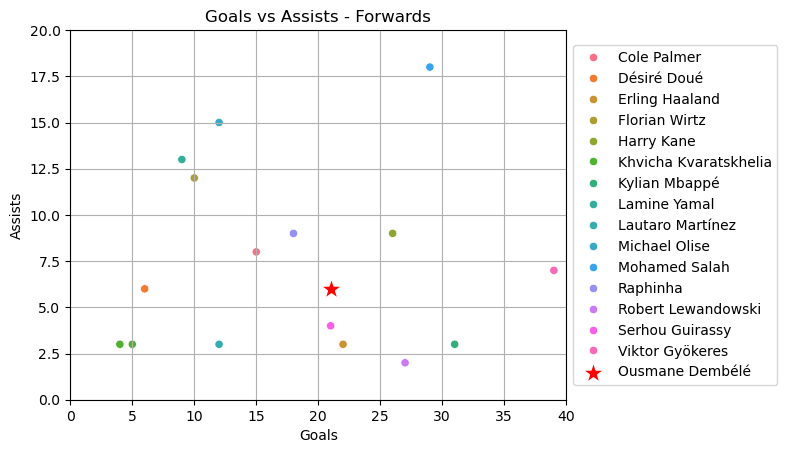

In [193]:
# Compare goals vs assists for all forwards
sns.scatterplot(fws2, x = 'Gls', y = 'Ast', hue = 'Player')
plt.grid(True)
plt.xlim(0,40)
plt.ylim(0,20)
plt.xlabel('Goals')
plt.ylabel('Assists')
plt.title('Goals vs Assists - Forwards')

sns.scatterplot(
    data= dembele,
    x='Gls',
    y='Ast',
    color='red',     
    s=300, label = 'Ousmane Dembélé', marker = '*'       
)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.savefig('goals_assists_forwards');

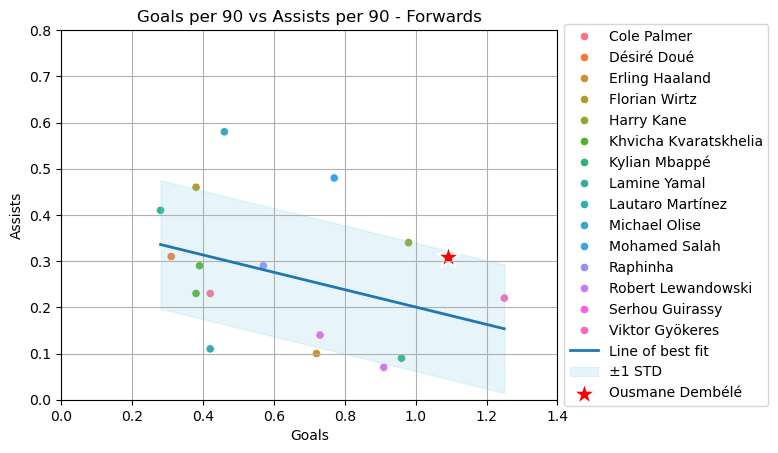

In [205]:
# Use curve fit and make a std for goals and assists per 90 minutes
def model(x,a,b):
    return a*x+b

x = fws2['GlsPer90'].values
y = fws2['AstPer90'].values

best_fit, ignore = curve_fit(model,x,y)
a_fit, b_fit = best_fit

y_pred = model(x,a_fit,b_fit)
y_fit = y - y_pred
std = np.std(y_fit)

# Compare goals per 90 mins vs assists per 90 minutes for all forwards
sns.scatterplot(fws2, x = 'GlsPer90', y = 'AstPer90', hue = 'Player')
plt.grid(True)
plt.xlim(0,1.4)
plt.ylim(0,.8)
plt.xlabel('Goals')
plt.ylabel('Assists')
plt.title('Goals per 90 vs Assists per 90 - Forwards')

x_line = np.linspace(min(x), max(x), 200)
y_line = model(x_line, a_fit, b_fit)
plt.plot(x_line, y_line, linewidth=2, label = 'Line of best fit')

plt.fill_between(x_line, y_line - std, y_line + std, alpha=0.2, color='skyblue', label='±1 STD')

sns.scatterplot(
    data=dembele,
    x='GlsPer90',
    y='AstPer90',
    color='red',     
    s=300, label = 'Ousmane Dembélé', marker = '*'       
)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5));

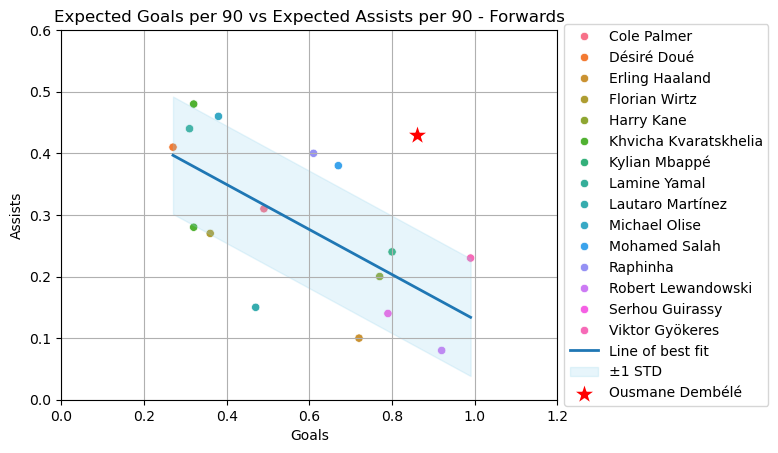

In [213]:
# Use curve fit and make a std for expected goals and assists per 90 minutes
def model(x,a,b):
    return a*x+b

x = fws2['xGPer90'].values
y = fws2['xAGPer90'].values

best_fit, ignore = curve_fit(model,x,y)
a_fit, b_fit = best_fit

y_pred = model(x,a_fit,b_fit)
y_fit = y - y_pred
std = np.std(y_fit)

# Comparing expected goals per 90 vs expected assists per 90 for all forwards, curve fit with std and show Dembele over the line
sns.scatterplot(fws2, x = 'xGPer90', y = 'xAGPer90', hue = 'Player')
plt.grid(True)
plt.xlim(0,1.2)
plt.ylim(0,.6)
plt.xlabel('Goals')
plt.ylabel('Assists')
plt.title('Expected Goals per 90 vs Expected Assists per 90 - Forwards')

x_line = np.linspace(min(x), max(x), 200)
y_line = model(x_line, a_fit, b_fit)
plt.plot(x_line, y_line, linewidth=2, label = 'Line of best fit')

plt.fill_between(x_line, y_line - std, y_line + std, alpha=0.2, color='skyblue', label='±1 STD')

sns.scatterplot(
    data= dembele,
    x='xGPer90',
    y='xAGPer90',
    color='red',     
    s=300, label = 'Ousmane Dembélé', marker = '*'       
)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5));

While progressive actions were unable to be normalized, I still compared the progressive actions for the top 5 players in votes. After comparing, we see that Dembele had the second-lowest progressive passes received, only behind his teammate, and had relatively progressive carries and progressive passes despite having fewer minutes than the others.

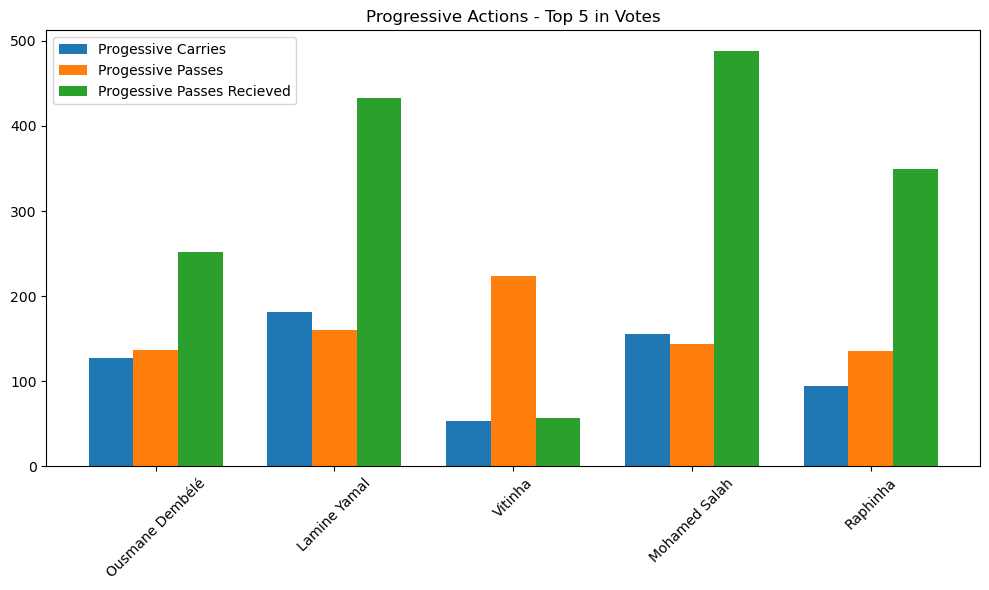

In [207]:
#Compare progressive actions by the top 5 nominees(in order of 1-5)
top5 = ballondor_player.loc[['Ousmane Dembélé', 'Lamine Yamal', 'Vitinha', 'Mohamed Salah', 'Raphinha']]
t5_pc = top5['PrgC']
t5_pp = top5['PrgP']
t5_ppr = top5['PrgR']

x = np.arange(len(top5))
width = 0.25

plt.figure(figsize=(10,6))
plt.bar(x - width, t5_pc, width, label = 'Progessive Carries')
plt.bar(x, t5_pp, width, label= 'Progessive Passes')
plt.bar(x + width, t5_ppr, width, label= 'Progessive Passes Recieved')

plt.xticks(x, top5.index, rotation=45)
plt.title('Progressive Actions - Top 5 in Votes')
plt.legend()
plt.tight_layout()
plt.savefig('top5_progessive')

Criteria #2 is related to team performance and achievements. After comparing the total players in each league earlier, there are 8 players in the French league. I created a pie chart using matplotlib and saw that all 8 of the players play for PSG, which is Dembele's team. To make it easier to view, I altered code from the matplotlib gallery to clip an image of the PSG logo on the pie chart. After, I compared the players on PSG using a scatterplot created with seaborn, and saw that Dembele was the standout player. To compare achievements, I collected data from FBRef, the same place used to collect the data for the Kaggle data set, and counted the number of trophies won by each team of the top 5 players. From that, I saw that PSG had the most trophies with 4. The most important of the 4 is the Champions League, which is the most prestigious and difficult club soccer tournament in the world.

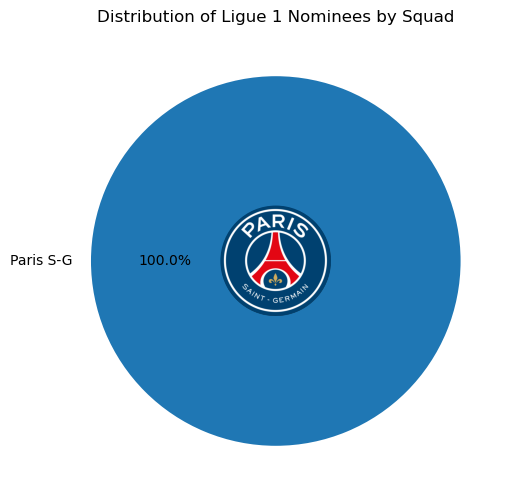

In [212]:
# Pie chart of teams represented in France, All PSG
import matplotlib.cbook as cbook
import matplotlib.patches as patches

squad_counts = france['Squad'].value_counts()
fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(squad_counts, labels=squad_counts.index, autopct='%1.1f%%')

# Load the image
image = plt.imread('/Users/owen/Downloads/Paris_Saint-Germain_F.C..svg.jpg')

im = ax.imshow(image, extent=[-0.3, 0.3, -0.3, 0.3], zorder=10)

patch = patches.Circle((0, 0), 0.3, transform=ax.transData) # I used reference code from the matplotlib gallery, cited in the references section.
im.set_clip_path(patch)

ax.axis('off')
plt.title("Distribution of Ligue 1 Nominees by Squad")
plt.savefig('psg.png')
plt.show()

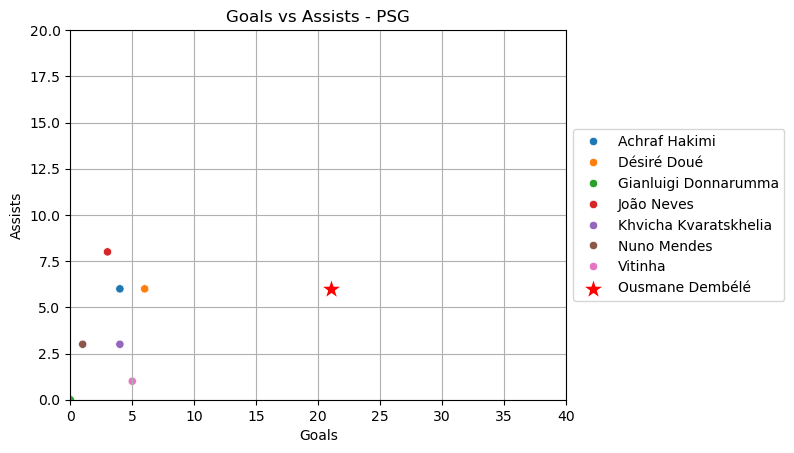

In [198]:
# Compare goals vs assists for all PSG players
sns.scatterplot(france2, x = 'Gls', y = 'Ast', hue = 'Player')
plt.grid(True)
plt.xlim(0,40)
plt.ylim(0,20)
plt.xlabel('Goals')
plt.ylabel('Assists')
plt.title('Goals vs Assists - PSG')

sns.scatterplot(
    data= dembele,
    x='Gls',
    y='Ast',
    color='red',     
    s=300, label = 'Ousmane Dembélé', marker = '*'       
)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.savefig('goals_asssist_psg.png');

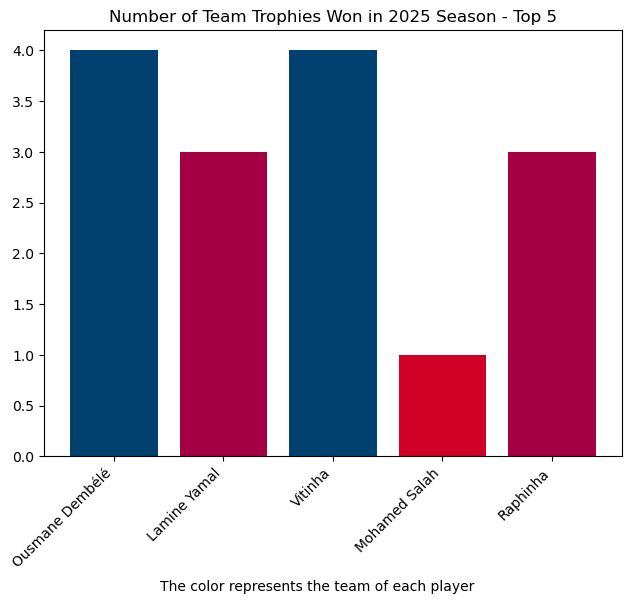

In [199]:
# Bar Chart of trophies for top 5
labels = ['Ousmane Dembélé', 'Lamine Yamal', 'Vitinha', 'Mohamed Salah', 'Raphinha']
sizes = [4, 3, 4, 1, 3]
colors = ['#004170',  # PSG blue
          '#A50044',  # Barca red
          '#004170',  # PSG blue
          '#D00027',  # Liverpool red
          '#A50044']  # Barca red

plt.bar(labels, sizes, color=colors)
plt.tight_layout()
plt.xticks(rotation=45, ha='right')
plt.title('Number of Team Trophies Won in 2025 Season - Top 5')
plt.figtext(.5, -0.2, 'The color represents the team of each player',
ha='center', fontsize=10
);

Lastly, to analyze the third criterion, I compared the total yellow cards for each player. However, I noticed that defenders received more cards, most likely due to the more aggressive nature of their position, rather than forwards having more class.

In [208]:
#Sort by most yellow cards
yellow = ballondor[['Player','CrdY']].sort_values(by='CrdY', ascending=False)
yellow

,Player,CrdY
2,Cole Palmer,7
3,Declan Rice,7
1,Alexis Mac Allister,6
28,Virgil van Dijk,5
9,Harry Kane,5
11,Jude Bellingham,5
0,Achraf Hakimi,4
4,Denzel Dumfries,4
27,Viktor Gyökeres,4
26,Serhou Guirassy,4


## Discussion and Conclusion

_(What did you learn from your results? What obstacles did you run into? What would you do differently next time? Clearly provide quantitative answers to your question(s)?  At least one of your questions should be answered with numbers.  That is, it is not sufficient to answer "yes" or "no", but rather to say something quantitative such as variable 1 increased roughly 10% for every 1 year increase in variable 2. Make sure to connect your results with your context!)_

I learned after examining the raw data that Dembele didn't stand out; however, after reviewing the per 90 and expected per 90 statistics, I found that Dembele was a standout player among the 30 nominees. Dembele's calf injury last season was a slight obstacle, as it reduced his statistics. Despite having 1,641 fewer minutes than fellow top 5 nominee, Mo Salah, Dembele made his impact seen by having 0.15 more goals and assists per 90 and 0.24 more expected goals and assists. Not only was Dembele a standout against the competition's standard deviation, but he also stood out against his own team. PSG won every competition they were a part of last year. Along with that, Dembele won the French league player of the season and the Champions League player of the season. Having all 8 French league players on PSG showed that his team was levels above their competition, however, that also made it harder for Dembele to be a standout player on a team with high internal competition. Furthermore, with such a strong team, Dembele received significantly fewer progressive passes than the other top 5 nominees, but more or around the same progressive carries and passes despite his minutes. Therefore, highlighting his impact on the field, as well as his creative flair. As for class and fair play, I was not able to make a conclusive discovery after comparing yellow cards. This is due to defenders having to risk getting cards more than forwards, and therefore having more. Additionally, I researched the charitable actions by the top 5 nominees, however, I was again not able to make a conclusive discovery because all players had some sort of charity, and I was unable to compare whos was 'better'. In conclusion, it is arguable that Dembele was the best player in standard time, but taking into account the first and second criteria, Ousmane Dembele won the 2025 Ballon d'Or by being the most impressive player on the most successful team. If I were to do something different next time, I would compare my findings with the 2024 Ballon d'Or data set to see if they are similar.

### References

_(List the source(s) for any data and/or literature cited in your project.  Ideally, this should be formatted using a formal citation format (MLA or APA or other, your choice!).   Multiple free online citation generators are available such as <a href="http://www.easybib.com/style">http://www.easybib.com/style</a>. **Important:** if you use **any** code that you find on the internet for your project you **must** cite it or you risk losing most/all of the points for you project.)_

“Clipping Images with Patches#.” Clipping Images with Patches - Matplotlib 3.10.7 Documentation, matplotlib.org/stable/gallery/images_contours_and_fields/image_clip_path.html#sphx-glr-gallery-images-contours-and-fields-image-clip-path-py. Accessed 29 Nov. 2025. 

“Ousmane Dembélé Stats, Goals, Records, Assists, Cups and More | Fbref.Com.” FBRef, Sports Reference, fbref.com/en/players/b19db005/Ousmane-Dembele. Accessed 29 Nov. 2025. 

Thakor, Siddhraj. “Ballon d’or 2025 Nominees Players Standard Stats.” Kaggle, 26 Sept. 2025, www.kaggle.com/datasets/siddhrajthakor/ballon-dor-2025-nominees-players-standard-stats. 

UEFA.com. “Country Coefficients: UEFA Rankings.” UEFA.Com, 19 July 2018, www.uefa.com/nationalassociations/uefarankings/country/?year=2026. 